# Smart Crop Advisor (PAI101)
Run top to bottom (Kernel -> Restart & Run All). Every graph is drawn inline and also saved to `source/models/figures/`.

| Part | Script | What it does | Main outputs |
|---|---|---|---|
| 1 | `01_prepare.py` | Clean both datasets, descriptive + exploratory + inferential analysis | `data/processed/*_clean.csv`, `eda.json` |
| 1b | `01b_synthetic.py` | Generate the **synthetic crop dataset** of weak and poor fields (needed because public data has only good fields) | `data/processed/synthetic_crop_dataset.csv`, `crop_profile.json` |
| 2 | `02_train.py` | Train + compare tree / forest / neural network, SHAP, K-means zones, yield regression, Edge AI numbers, label poisoning, suitability model, export to the browser | `metrics.json`, `*.joblib`, `frontend/data/model.json` |
| 3 | `03_analysis.py` | **Statistical analysis**, **ablation study**, **cross-dataset validation** | `analysis.json`, `stat_*.png`, `ablation_*.png`, `cross_dataset.png` |

**Key idea.** The public dataset contains only *good* fields for each crop, so a classifier alone cannot say "this field is bad for
rice". The synthetic dataset adds poor and marginal fields (clearly labelled as generated by us), and the suitability model learns
from both, giving a 0-100% score per crop that falls for poor fits and rises as the readings improve.


# 01 - Data preparation and analysis
Cleans both datasets, runs descriptive / exploratory / inferential analysis.
Run from anywhere: `python source/notebooks/01_prepare.py` (also opens as cells in PyCharm/VS Code).

**What this part does:** loads the two raw datasets, removes bad rows, describes the data, draws exploratory graphs and runs
the inferential tests the brief asks for. **Why:** a model is only as good as its data, and the brief requires descriptive,
exploratory and inferential analysis before any modelling. **Outputs:** `data/processed/*_clean.csv`,
`source/models/eda.json` and the graphs in `source/models/figures/`.


In [1]:
import json
from pathlib import Path

import matplotlib
pass  # inline backend in the notebook
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, OUT = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG = ROOT / "source" / "models" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
report = {}

## Crop recommendation data: check missing, duplicates, impossible values
**What:** count missing values, duplicate rows, pH outside 0-14, humidity outside 0-100 and negative readings, then drop any
offending rows. **Why:** impossible values would silently corrupt every later step (this is also the first AI-security
defence: reject out-of-range data). **Result:** 2,200 rows, 0 missing, 0 duplicates, 0 impossible values, so nothing is dropped.
The same range rules are reused by the web app to reject spoofed sensor readings.


In [2]:
crop = pd.read_csv(RAW / "crop_recommendation.csv")
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
report["crop_raw"] = {
    "rows": len(crop),
    "missing": int(crop.isna().sum().sum()),
    "duplicates": int(crop.duplicated().sum()),
    "ph_out_of_0_14": int((~crop.ph.between(0, 14)).sum()),
    "humidity_out_of_0_100": int((~crop.humidity.between(0, 100)).sum()),
    "negative_values": int((crop[FEATURES] < 0).any(axis=1).sum()),
}
crop = crop.drop_duplicates().dropna()
crop = crop[crop.ph.between(0, 14) & crop.humidity.between(0, 100) & (crop[FEATURES] >= 0).all(axis=1)]
crop.to_csv(OUT / "crop_clean.csv", index=False)
report["crop_clean_rows"] = len(crop)

## Descriptive + exploratory
**What:** summary statistics (count, mean, std, min, quartiles, max) for the 7 readings, samples per crop (100 each, so the
classes are balanced), mean reading per crop, a correlation heatmap, histograms and a rainfall-by-crop box plot.
**Why:** to see the ranges, spot outliers, and learn which readings separate crops. **Graphs:** `correlation.png`
(Pearson r between readings; P and K are strongly correlated because several fruit crops need both), `histograms.png`
(shape of each reading) and `rainfall_by_crop.png` (rice, jute and coconut are wet, chickpea and mothbeans are dry).


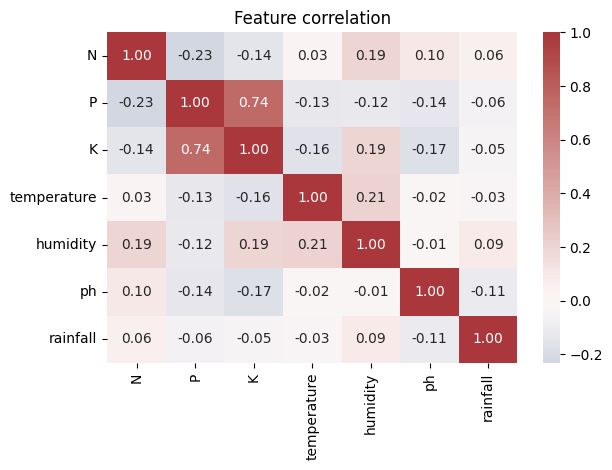

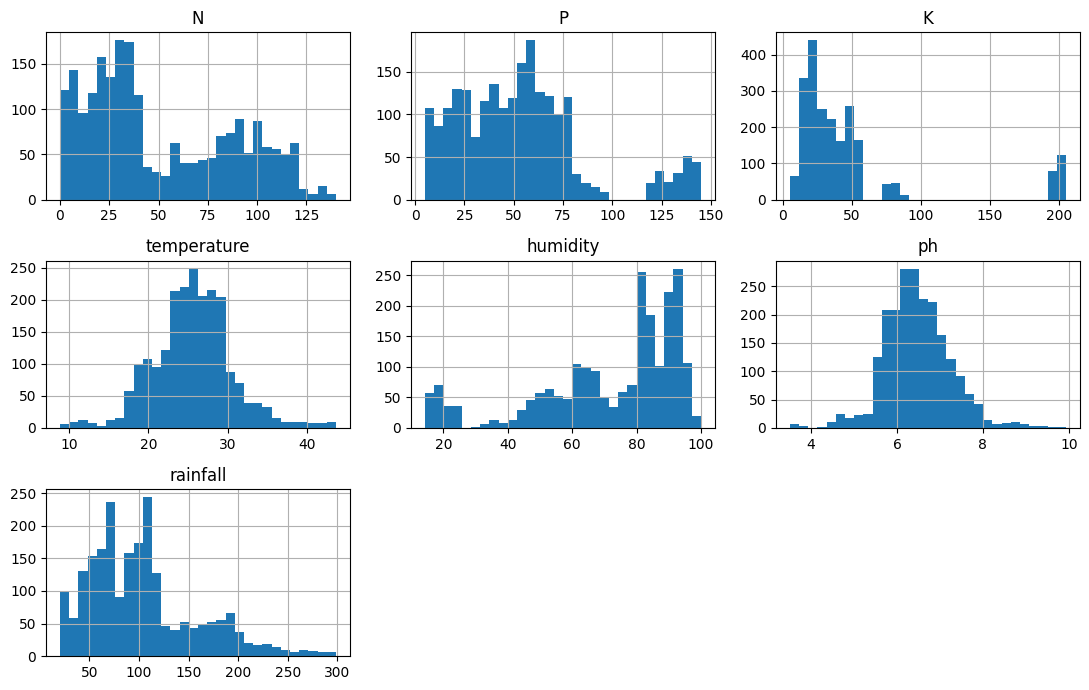

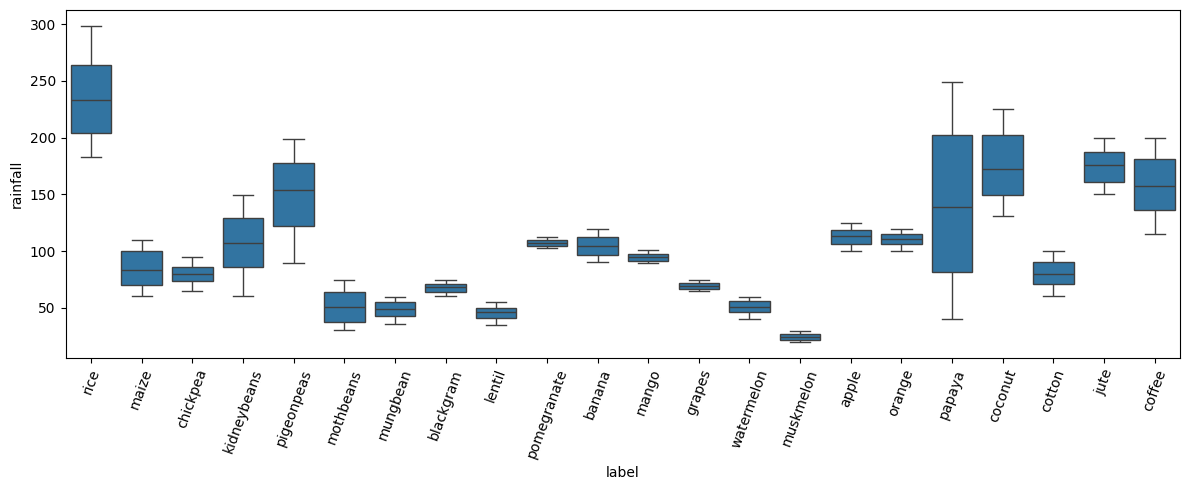

In [3]:
report["describe"] = crop[FEATURES].describe().round(3).to_dict()
report["samples_per_crop"] = crop.label.value_counts().to_dict()
report["mean_per_crop"] = crop.groupby("label")[FEATURES].mean().round(2).to_dict("index")

sns.heatmap(crop[FEATURES].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Feature correlation"); plt.tight_layout(); plt.savefig(FIG / "correlation.png", dpi=120); plt.show()

crop[FEATURES].hist(bins=30, figsize=(11, 7))
plt.tight_layout(); plt.savefig(FIG / "histograms.png", dpi=120); plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(data=crop, x="label", y="rainfall")
plt.xticks(rotation=70); plt.tight_layout(); plt.savefig(FIG / "rainfall_by_crop.png", dpi=120); plt.show()

## Inferential: does rainfall differ between rice and chickpea? (Welch t-test + 95% CI) and across all crops (ANOVA)
**What:** a Welch t-test (does not assume equal variances) compares rice and chickpea rainfall, with a 95% confidence
interval for the difference; a one-way ANOVA tests whether mean rainfall differs across all 22 crops.
**Why:** the brief asks for inferential analysis. **Result:** rice averages 236 mm vs chickpea 80 mm, t = 44.35,
p = 7.6e-72, 95% CI of the difference [149.15, 163.10] mm; ANOVA F = 605.5, p ~ 0. So crops genuinely differ in rainfall.
(`03_analysis.py` adds effect sizes, which a p-value cannot give.)


In [4]:
rice, chick = (crop.loc[crop.label == c, "rainfall"] for c in ("rice", "chickpea"))
t = stats.ttest_ind(rice, chick, equal_var=False)
ci = t.confidence_interval(0.95)
report["ttest_rice_vs_chickpea_rainfall"] = {
    "mean_rice": round(rice.mean(), 2), "mean_chickpea": round(chick.mean(), 2),
    "t": round(t.statistic, 2), "p": float(t.pvalue),
    "ci95_mean_difference": [round(ci.low, 2), round(ci.high, 2)],
}
anova = stats.f_oneway(*(g.rainfall.values for _, g in crop.groupby("label")))
report["anova_rainfall_across_crops"] = {"F": round(anova.statistic, 1), "p": float(anova.pvalue)}

## Yield data
**What:** loads the FAO-derived country yield table (28,242 rows), drops the leftover index column, 2,310 duplicates and
rows with non-positive yield or negative inputs, leaving 25,932 rows. **Why:** the yield regression (Module 2) needs clean,
physically sensible rows. **Output:** `yield_clean.csv` and `yield_correlation.png` (correlation of yield with rainfall -0.00, pesticides 0.07, temperature -0.11, year 0.09: all near zero, so crop type, not weather, explains most of the yield variance).


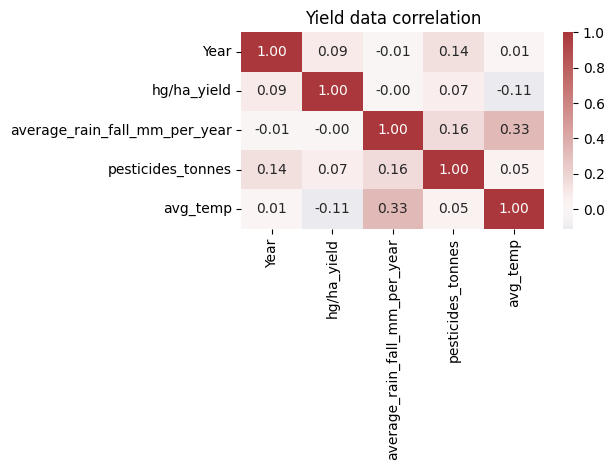

{
  "crop_raw": {
    "rows": 2200,
    "missing": 0,
    "duplicates": 0,
    "ph_out_of_0_14": 0,
    "humidity_out_of_0_100": 0,
    "negative_values": 0
  },
  "crop_clean_rows": 2200,
  "yield_raw": {
    "rows": 28242,
    "missing": 0,
    "duplicates": 2310
  },
  "yield_clean_rows": 25932,
  "ttest_rice_vs_chickpea_rainfall": {
    "mean_rice": 236.18,
    "mean_chickpea": 80.06,
    "t": 44.35,
    "p": 7.636899734027873e-72,
    "ci95_mean_difference": [
      149.15,
      163.1
    ]
  },
  "anova_rainfall_across_crops": {
    "F": 605.5,
    "p": 0.0
  }
}


In [5]:
y = pd.read_csv(RAW / "yield_df.csv")
y = y.drop(columns=[c for c in y.columns if c.startswith("Unnamed")])  # leftover index column
report["yield_raw"] = {"rows": len(y), "missing": int(y.isna().sum().sum()), "duplicates": int(y.duplicated().sum())}
y = y.drop_duplicates().dropna()
y = y[(y["hg/ha_yield"] > 0) & (y.average_rain_fall_mm_per_year >= 0) & (y.pesticides_tonnes >= 0)]
y.to_csv(OUT / "yield_clean.csv", index=False)
report["yield_clean_rows"] = len(y)
report["yield_items"] = y.Item.value_counts().to_dict()
report["yield_describe"] = y.describe().round(2).to_dict()

sns.heatmap(y.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Yield data correlation"); plt.tight_layout(); plt.savefig(FIG / "yield_correlation.png", dpi=120); plt.show()

(ROOT / "source" / "models" / "eda.json").write_text(json.dumps(report, indent=2, default=str))
print(json.dumps({k: report[k] for k in ("crop_raw", "crop_clean_rows", "yield_raw", "yield_clean_rows",
                                         "ttest_rice_vs_chickpea_rainfall", "anova_rainfall_across_crops")}, indent=2))

# 01b - Synthetic crop dataset (weak and poor fields)
**This dataset is generated by us, not collected.** No public dataset we could find (Kaggle, Hugging Face, Mendeley)
contains weak or unsuitable fields: the Kaggle crop data only holds good fields for each crop.
So we add the missing side ourselves and call the result `synthetic_crop_dataset.csv`.

Rows (100 per crop, 2,200 total, same size as the real data):
* 40 `real_good`      - real rows of the crop (the strong conditions)
* 21 `other_crop`     - the conditions of each of the 21 other crops, so every crop x crop pair is covered once
* 20 `blend`          - the crop's own real row mixed 20-70% with another crop's conditions (marginal fields)
* 10 `single_extreme` - a real row of the crop where ONE reading is pushed to the dataset minimum or maximum (drought, frost, acid soil...)
* 9  `one_reading_off`- a real row of the crop where 1-2 readings are replaced by another crop's values

`suitability` (0-1) is NOT random. It comes from one formula: how far the readings are from the crop's usual profile
(median and spread from the real data). Close = near 1, far = near 0. Under 0.30 means "unsuitable".
Run: `python source/notebooks/01b_synthetic.py` (after 01_prepare.py)


In [6]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
SEED = 42
rng = np.random.default_rng(SEED)

real = pd.read_csv(PROC / "crop_clean.csv")
crops = sorted(real.label.unique())
lo, hi = real[FEATURES].min(), real[FEATURES].max()
# crop profile: median and spread (spread floored at 8% of the dataset range so very tight crops are not hypersensitive)
med = real.groupby("label")[FEATURES].median()
scale = real.groupby("label")[FEATURES].std().clip(lower=0.08 * (hi - lo), axis=1)


def suitability(crop, x):
    """1 = typical field for this crop, 0 = conditions of a very different crop. Mean deviation plus the worst reading."""
    z = (np.asarray(x, float) - med.loc[crop].values) / scale.loc[crop].values
    d2 = 0.5 * np.mean(z ** 2) + 0.5 * np.max(z ** 2) / 3.5
    return float(np.exp(-d2 / 2.6))


def tier(s):
    return "suitable" if s >= 0.70 else "marginal" if s >= 0.30 else "unsuitable"

In [7]:
rows = []


def add(crop, x, how, other=""):
    x = np.clip(x, lo.values, hi.values)
    s = round(suitability(crop, x), 3)
    rows.append({"crop": crop, **dict(zip(FEATURES, np.round(x, 2))), "suitability": s, "tier": tier(s),
                 "how_generated": how, "borrowed_from": other})


pick = lambda c: real[real.label == c][FEATURES].sample(1, random_state=int(rng.integers(1 << 30))).values[0]
for c in crops:
    own = real[real.label == c][FEATURES]
    for _, r in own.sample(40, random_state=SEED).iterrows():
        add(c, r.values, "real_good")
    for o in crops:
        if o != c:
            add(c, pick(o), "other_crop", o)  # every crop x other-crop pair appears exactly once
    for _ in range(20):
        o = rng.choice([k for k in crops if k != c]); a = rng.uniform(0.2, 0.7)
        add(c, (1 - a) * pick(c) + a * pick(o), "blend", o)
    for _ in range(10):  # one reading ruined, everything else typical: the field must still score low
        x = pick(c); j = rng.integers(7); x[j] = lo.values[j] if rng.random() < 0.5 else hi.values[j]
        add(c, x, "single_extreme")
    for _ in range(9):
        o = rng.choice([k for k in crops if k != c]); x = pick(c); donor = pick(o)
        for j in rng.choice(7, size=rng.integers(1, 3), replace=False):
            x[j] = donor[j]
        add(c, x, "one_reading_off", o)

syn = pd.DataFrame(rows)
syn.to_csv(PROC / "synthetic_crop_dataset.csv", index=False)

## Sanity checks: are the labels sensible?


In [8]:
print(len(syn), "rows;", syn.crop.nunique(), "crops;", syn.groupby("crop").size().unique(), "per crop")
print(syn.tier.value_counts().to_string())
print(syn.groupby("how_generated").suitability.describe()[["count", "mean", "min", "50%", "max"]].round(2).to_string())
pairs = syn[syn.how_generated == "other_crop"].groupby(["crop", "borrowed_from"]).size()
assert len(pairs) == len(crops) * (len(crops) - 1), "every crop x other-crop pair must be present"
print("crop x other-crop pairs covered:", len(pairs), "of", len(crops) * (len(crops) - 1))
oc = syn[syn.how_generated == "other_crop"]
print(f"other crop's conditions scoring under 0.30: {(oc.suitability < .3).mean():.0%} (the rest are genuinely similar crops)")
print("real good fields scoring 0.70+:", f"{(syn[syn.how_generated == 'real_good'].suitability >= .7).mean():.0%}")

2200 rows; 22 crops; [100] per crop
tier
suitable      1037
unsuitable     787
marginal       376
                 count  mean   min   50%   max
how_generated                                 
blend            440.0  0.44  0.00  0.44  0.94
one_reading_off  198.0  0.49  0.00  0.60  0.93
other_crop       462.0  0.08  0.00  0.02  0.80
real_good        880.0  0.84  0.62  0.84  0.99
single_extreme   220.0  0.23  0.00  0.06  0.92
crop x other-crop pairs covered: 462 of 462
other crop's conditions scoring under 0.30: 91% (the rest are genuinely similar crops)
real good fields scoring 0.70+: 95%


In [9]:
import json  # crop profile (median, spread) is shared with training and the browser
(PROC / "crop_profile.json").write_text(json.dumps(
    {c: {"med": med.loc[c].round(4).tolist(), "scale": scale.loc[c].round(4).tolist()} for c in crops}))

3065

## Graph: how the synthetic scores are distributed
One histogram per row type. Real good fields sit near 1; other crops' conditions pile up near 0; blends and
one-reading-off rows spread in between. The dotted lines are the 30% and 70% tier boundaries.


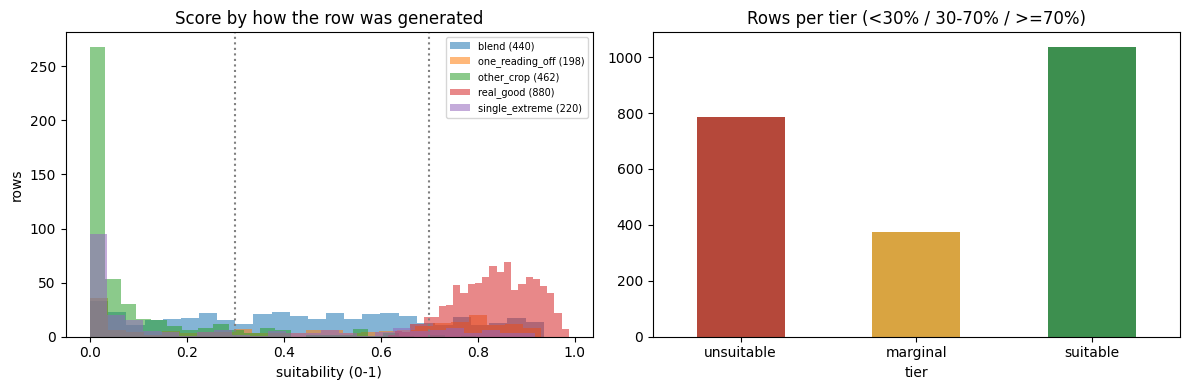

In [10]:
import matplotlib
pass  # inline backend in the notebook
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, g in syn.groupby("how_generated"):
    ax[0].hist(g.suitability, bins=25, alpha=0.55, label=f"{k} ({len(g)})")
ax[0].axvline(0.3, color="grey", ls=":"); ax[0].axvline(0.7, color="grey", ls=":")
ax[0].set_xlabel("suitability (0-1)"); ax[0].set_ylabel("rows"); ax[0].legend(fontsize=7); ax[0].set_title("Score by how the row was generated")
syn.tier.value_counts().reindex(["unsuitable", "marginal", "suitable"]).plot.bar(ax=ax[1], color=["#b5483a", "#d9a441", "#3d8f4f"])
ax[1].set_title("Rows per tier (<30% / 30-70% / >=70%)"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(ROOT / "source" / "models" / "figures" / "synthetic_scores.png", dpi=120); plt.show()

# 02 - Train, compare, explain, export
Modules 1-4, 6-8. Needs `01_prepare.py` to have run. Writes metrics + figures to source/models
and the browser model to frontend/data/model.json.

**What this part does:** trains and compares the classifiers (Modules 1, 3), explains them (Module 6), clusters farms
(Module 4), fits the yield regression (Module 2), measures Edge-AI size/speed (Module 7), runs the label-poisoning demo
(Module 8), trains the suitability model, and exports everything for the web app. **Why:** these are the course's ML
topics; each is evaluated on data the model never saw. **Outputs:** `metrics.json`, `.joblib` models, figures, `model.json`.


In [11]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
pass  # inline backend in the notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score, homogeneity_score)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore", message="X does not have valid feature names")
SEED = 42
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
PROC, MODELS = ROOT / "data" / "processed", ROOT / "source" / "models"
FIG = MODELS / "figures"
WEB = ROOT / "frontend" / "data"
WEB.mkdir(parents=True, exist_ok=True)
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
M = {}  # all metrics land here

## Module 1 - decision tree (depth chosen by cross-validation) vs random forest
**What:** 80/20 stratified split (every crop in both sets, fixed seed 42). Tree depth 3-12 is compared by 5-fold CV on the
training set only; the best depth (11) is kept so the tree is not just memorising (overfitting control). A 30-tree random
forest is trained for comparison. **Result:** tree 97.7%, forest 99.1% test accuracy. **Graphs:** `confusion_rf.png`
(rows = true crop, columns = predicted; a bright diagonal means correct), `tree_top.png` (first 3 levels of the tree = readable
rules), `feature_importance.png` (how much each reading reduces impurity across the forest; rainfall and humidity lead).


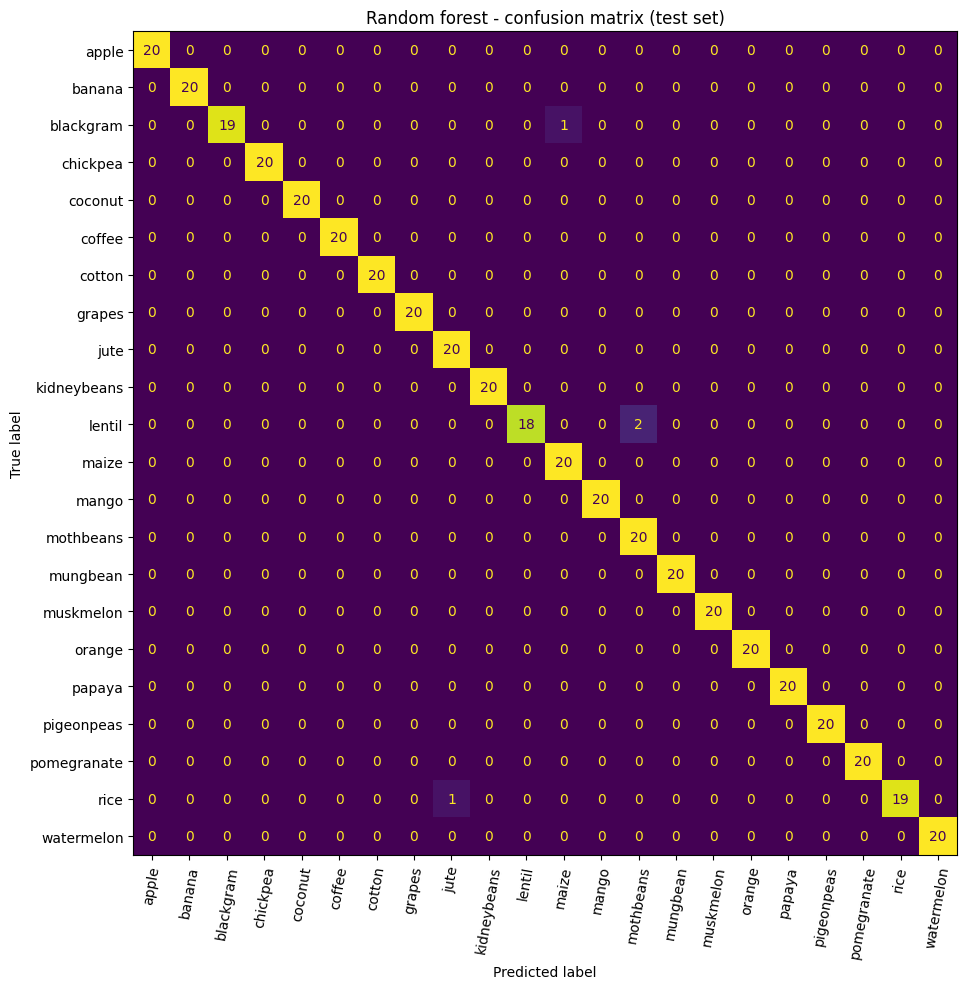

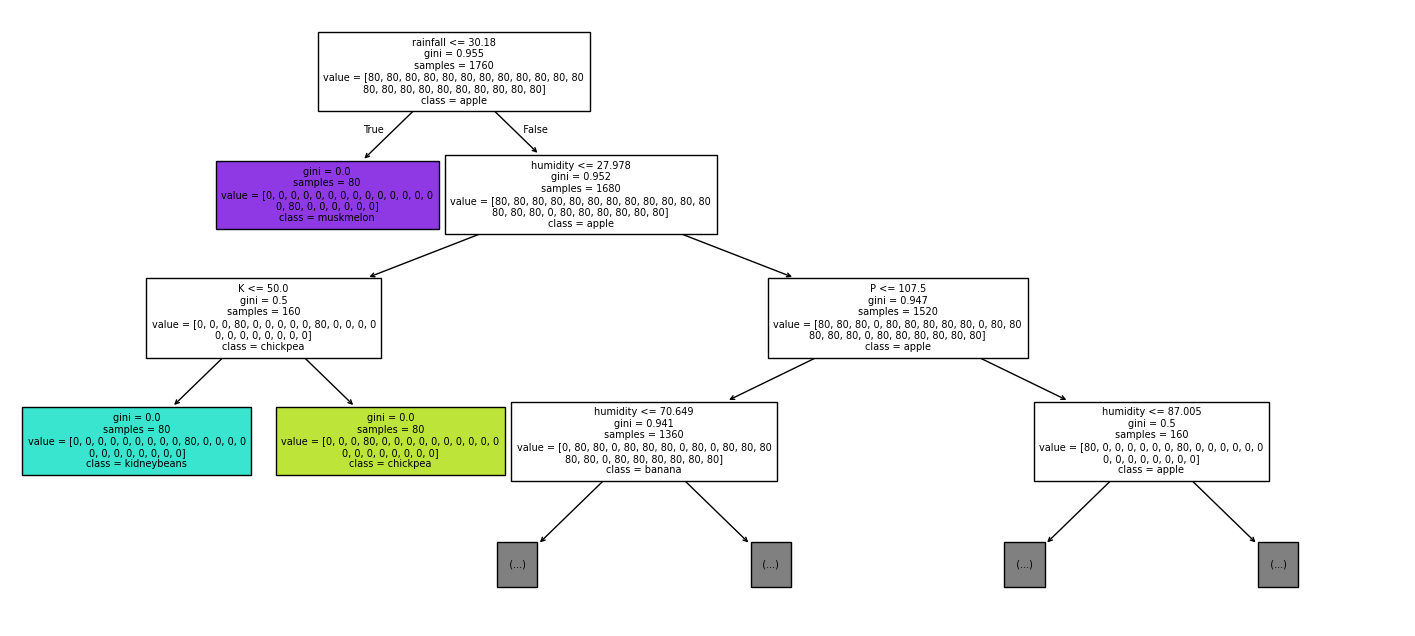

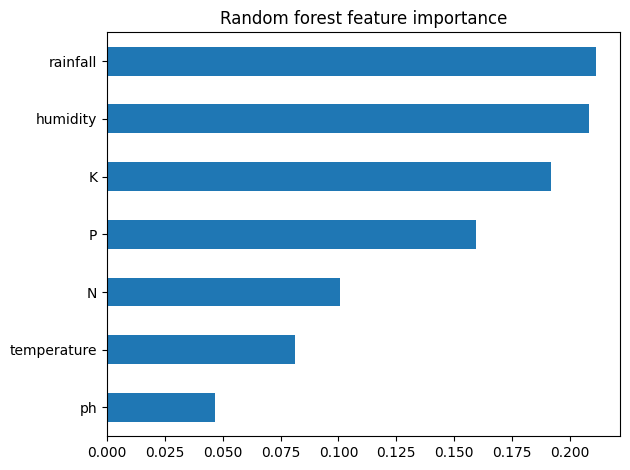

In [12]:
crop = pd.read_csv(PROC / "crop_clean.csv")
X, y = crop[FEATURES], crop.label
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)  # stratified 80/20

cv = {d: cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), Xtr, ytr, cv=5).mean()
      for d in range(3, 13)}
depth = max(cv, key=cv.get)
M["tree_depth_cv"] = {str(d): round(s, 4) for d, s in cv.items()}
M["tree_depth_chosen"] = depth

t0 = time.time(); dt = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(Xtr, ytr); dt_time = time.time() - t0
t0 = time.time(); rf = RandomForestClassifier(n_estimators=30, max_depth=10, random_state=SEED).fit(Xtr, ytr); rf_time = time.time() - t0
M["decision_tree"] = {"accuracy": round(accuracy_score(yte, dt.predict(Xte)), 4), "train_seconds": round(dt_time, 3),
                      "train_accuracy": round(dt.score(Xtr, ytr), 4)}
M["random_forest"] = {"accuracy": round(accuracy_score(yte, rf.predict(Xte)), 4), "train_seconds": round(rf_time, 3),
                      "train_accuracy": round(rf.score(Xtr, ytr), 4)}
M["rf_per_crop"] = classification_report(yte, rf.predict(Xte), output_dict=True, zero_division=0)

ConfusionMatrixDisplay.from_predictions(yte, rf.predict(Xte), xticks_rotation=80, colorbar=False,
                                        ax=plt.subplots(figsize=(11, 10))[1])
plt.title("Random forest - confusion matrix (test set)"); plt.tight_layout()
plt.savefig(FIG / "confusion_rf.png", dpi=110); plt.show()

plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=FEATURES, class_names=list(dt.classes_), filled=True, max_depth=3, fontsize=7)
plt.savefig(FIG / "tree_top.png", dpi=110); plt.show()

imp = pd.Series(rf.feature_importances_, FEATURES).sort_values()
imp.plot.barh(title="Random forest feature importance"); plt.tight_layout()
plt.savefig(FIG / "feature_importance.png", dpi=110); plt.show()
M["feature_importance"] = imp.round(4).to_dict()

## Module 3 - neural network (scaler fit on the training set only)
**What:** a feed-forward network, 7 inputs -> 64 -> 32 hidden units (ReLU) -> 22 softmax outputs. Inputs are standardised
with a scaler fitted on the training set only (fitting on all data would leak test information). **Result:** 99.1% accuracy,
408 epochs, about 2 s training. **Graph:** `mlp_loss.png`, the training loss per epoch; a smooth fall to near zero means it converged.


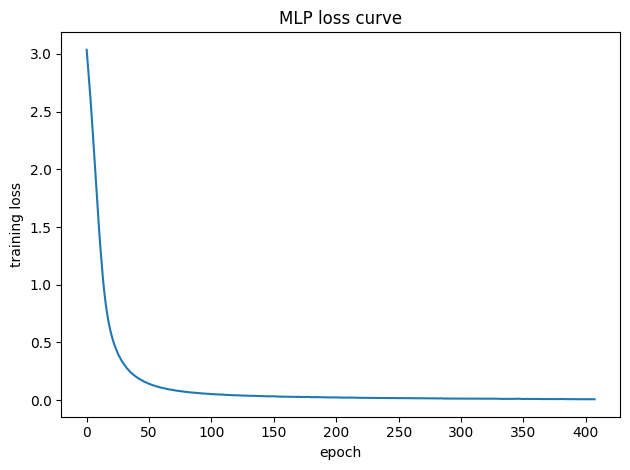

In [13]:
scaler = StandardScaler().fit(Xtr)
t0 = time.time()
mlp = MLPClassifier((64, 32), activation="relu", max_iter=500, random_state=SEED).fit(scaler.transform(Xtr), ytr)
mlp_time = time.time() - t0
M["neural_net"] = {"accuracy": round(mlp.score(scaler.transform(Xte), yte), 4), "train_seconds": round(mlp_time, 3),
                   "train_accuracy": round(mlp.score(scaler.transform(Xtr), ytr), 4), "epochs": mlp.n_iter_}
plt.plot(mlp.loss_curve_); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.title("MLP loss curve")
plt.tight_layout(); plt.savefig(FIG / "mlp_loss.png", dpi=110); plt.show()

## Module 6 - SHAP on the random forest (offline; the web demo explains with per-reading score cost instead)
**What:** SHAP assigns each reading a share of credit for each prediction (Shapley values from game theory); the mean of the
absolute values over 200 test fields ranks the readings. **Why:** explainable AI. **Graph:** `shap_importance.png`
(humidity, K and P matter most, pH least, which agrees with the ANOVA effect sizes in part 03; the forest's own importance ranks rainfall first, so different explainers weigh correlated readings differently).


C:\Users\super\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


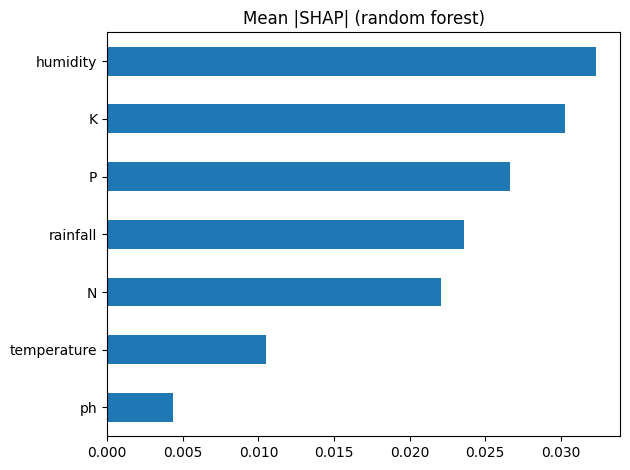

In [14]:
try:
    import shap
    sv = shap.TreeExplainer(rf).shap_values(Xte.iloc[:200])
    sv = np.abs(np.array(sv))
    mean_abs = sv.mean(axis=tuple(i for i in range(sv.ndim) if sv.shape[i] != len(FEATURES)))
    M["shap_mean_abs"] = dict(zip(FEATURES, np.round(mean_abs, 4).tolist()))
    pd.Series(mean_abs, FEATURES).sort_values().plot.barh(title="Mean |SHAP| (random forest)")
    plt.tight_layout(); plt.savefig(FIG / "shap_importance.png", dpi=110); plt.show()
except Exception as e:  # shap is optional
    M["shap_mean_abs"] = f"skipped: {e}"

## Module 4 - K-means zones (labels not used for fitting)
**What:** standardise the 7 readings, run K-means for k = 2..10, and choose k by the silhouette score (restricted to k >= 4
because k = 2 or 3 gives zones too coarse to describe in words). Each zone is described by its centre (readings more than
0.5 standard deviations from average become words such as "hot, humid, high rainfall"). **Result:** k = 10, silhouette
0.349, homogeneity vs the true crops 0.64. **Graphs:** `kmeans_k.png` (elbow = inertia, silhouette per k) and
`kmeans_pca.png` (the zones drawn in 2-D after PCA).


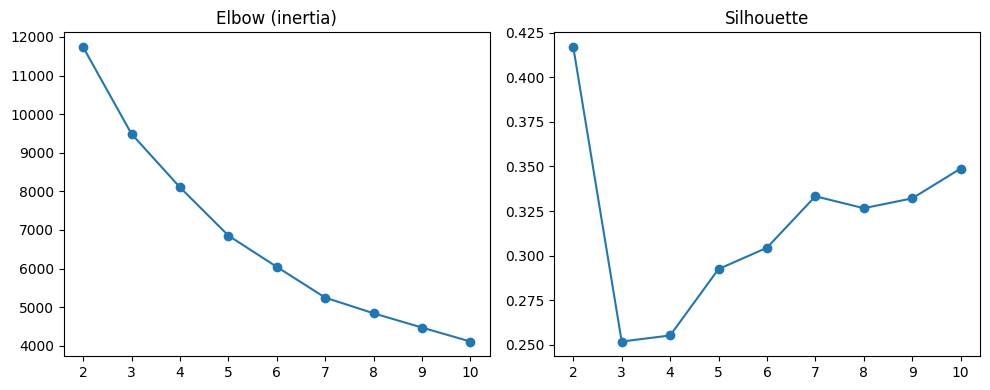

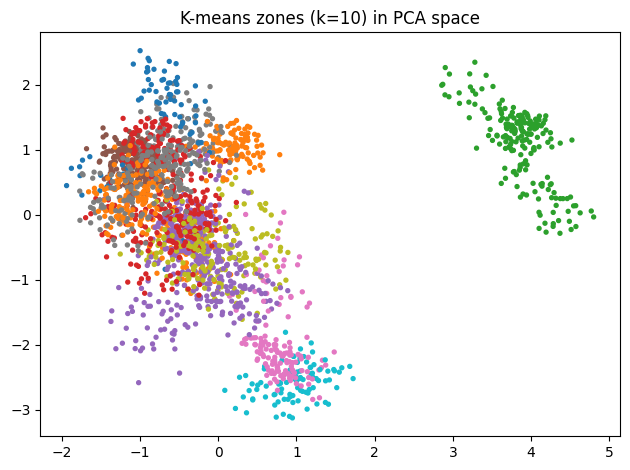

C:\Users\super\AppData\Local\Temp\ipykernel_25664\211350806.py:24: DeprecationWarning: In future, it will be an error for 'np.bool' scalars to be interpreted as an index
  traits = [WORDS[f][c[j] > 0] for j, f in enumerate(FEATURES) if abs(c[j]) >= 0.5]
C:\Users\super\AppData\Local\Temp\ipykernel_25664\211350806.py:24: DeprecationWarning: In future, it will be an error for 'np.bool' scalars to be interpreted as an index
  traits = [WORDS[f][c[j] > 0] for j, f in enumerate(FEATURES) if abs(c[j]) >= 0.5]
C:\Users\super\AppData\Local\Temp\ipykernel_25664\211350806.py:24: DeprecationWarning: In future, it will be an error for 'np.bool' scalars to be interpreted as an index
  traits = [WORDS[f][c[j] > 0] for j, f in enumerate(FEATURES) if abs(c[j]) >= 0.5]
C:\Users\super\AppData\Local\Temp\ipykernel_25664\211350806.py:24: DeprecationWarning: In future, it will be an error for 'np.bool' scalars to be interpreted as an index
  traits = [WORDS[f][c[j] > 0] for j, f in enumerate(FEATURES) if ab

In [15]:
Xs_all = StandardScaler().fit(X)
Z = Xs_all.transform(X)
ks = range(2, 11)  # plotted for the elbow; k is picked from 4+ because k=2/3 gives zones too coarse to describe
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
k_best = max((k for k in ks if k >= 4), key=lambda k: sil[list(ks).index(k)])
km = KMeans(k_best, n_init=10, random_state=SEED).fit(Z)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette")
plt.tight_layout(); plt.savefig(FIG / "kmeans_k.png", dpi=110); plt.show()
P = PCA(2, random_state=SEED).fit_transform(Z)
plt.scatter(P[:, 0], P[:, 1], c=km.labels_, cmap="tab10", s=8); plt.title(f"K-means zones (k={k_best}) in PCA space")
plt.tight_layout(); plt.savefig(FIG / "kmeans_pca.png", dpi=110); plt.show()

WORDS = {"N": ("low nitrogen", "high nitrogen"), "P": ("low phosphorus", "high phosphorus"),
         "K": ("low potassium", "high potassium"), "temperature": ("cool", "hot"),
         "humidity": ("dry air", "humid"), "ph": ("acidic soil", "alkaline soil"),
         "rainfall": ("low rainfall", "high rainfall")}
zones = []
for i, c in enumerate(km.cluster_centers_):
    traits = [WORDS[f][c[j] > 0] for j, f in enumerate(FEATURES) if abs(c[j]) >= 0.5]
    crops = crop.label[km.labels_ == i].value_counts()
    zones.append({"id": i, "size": int((km.labels_ == i).sum()), "center": [round(float(v), 4) for v in c],
                  "description": ", ".join(traits) or "close to average conditions",
                  "top_crops": crops.head(4).index.tolist()})
M["kmeans"] = {"k": k_best, "silhouette_by_k": {str(k): round(s, 4) for k, s in zip(ks, sil)},
               "homogeneity_vs_crop": round(homogeneity_score(y, km.labels_), 4), "zones": zones}

## Module 2 - yield regression (linear + ridge, one-hot crop type); random forest only as a reference
**What:** predict yield (hg/ha) from crop type (one-hot encoded), annual rainfall, pesticides and average temperature, with
linear and Ridge regression; a random forest is a reference, not shipped. **Metrics:** MAE (average error), RMSE (penalises big
errors) and R2 (share of variance explained). **Result:** linear R2 0.638, MAE 32,040 hg/ha (= 3.2 t/ha), RMSE 51,004;
Ridge is identical; the forest reaches R2 0.967 but is too large for the browser and shows the data has non-linear structure.


In [16]:
yd = pd.read_csv(PROC / "yield_clean.csv")
YF = ["average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
Ytr, Yte = train_test_split(yd, test_size=0.2, stratify=yd.Item, random_state=SEED)
prep = ColumnTransformer([("item", OneHotEncoder(handle_unknown="ignore"), ["Item"]), ("num", "passthrough", YF)])
M["yield"] = {}
fitted = {}
for name, est in [("linear", LinearRegression()), ("ridge", Ridge(alpha=1.0)),
                  ("random_forest_reference", RandomForestRegressor(100, max_depth=14, n_jobs=-1, random_state=SEED))]:
    pipe = make_pipeline(prep, est).fit(Ytr[["Item"] + YF], Ytr["hg/ha_yield"])
    p = pipe.predict(Yte[["Item"] + YF])
    M["yield"][name] = {"MAE": round(mean_absolute_error(Yte["hg/ha_yield"], p)),
                        "RMSE": round(mean_squared_error(Yte["hg/ha_yield"], p) ** 0.5),
                        "R2": round(r2_score(Yte["hg/ha_yield"], p), 4)}
    fitted[name] = pipe
lin = fitted["linear"]
items = lin[0].named_transformers_["item"].categories_[0].tolist()
coef = lin[-1].coef_.tolist()

## Module 7 - Edge AI numbers; Module 8 - label-poisoning demo
**Edge AI (Module 7):** each model is saved with joblib and timed: tree 15.7 KB / 0.07 ms per prediction, forest 773 KB / 1.2 ms,
network 121 KB / 0.16 ms. Small and fast means it can run on a low-cost device with no internet.
**Label poisoning (Module 8):** a share of training labels (0-30%) is replaced with random wrong crops and the tree is retrained.
**Result:** tree accuracy falls 97.7% -> 95.5% -> 92.5% -> 81.1% at 0, 5, 10, 20% poisoned (82.5% at 30%, a noisy tail),
showing why training data must come from trusted sources.


In [17]:
def predict_ms(fn, n=200):
    t0 = time.perf_counter()
    for row in Xte.values[:n]:
        fn(row.reshape(1, -1))
    return round((time.perf_counter() - t0) / n * 1000, 3)

for name, mdl in [("decision_tree", dt), ("random_forest", rf), ("neural_net", mlp)]:
    f = MODELS / f"{name}.joblib"
    joblib.dump(mdl, f)
    M[name]["file_kb"] = round(f.stat().st_size / 1024, 1)
M["decision_tree"]["predict_ms"] = predict_ms(dt.predict)
M["random_forest"]["predict_ms"] = predict_ms(rf.predict)
M["neural_net"]["predict_ms"] = predict_ms(lambda r: mlp.predict(scaler.transform(r)))

rng = np.random.default_rng(SEED)
poison = {}
for frac in (0, 0.05, 0.10, 0.20, 0.30):
    yp = ytr.copy().values
    idx = rng.choice(len(yp), int(frac * len(yp)), replace=False)
    yp[idx] = rng.choice(np.unique(yp), len(idx))  # random wrong labels
    poison[str(frac)] = round(DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(Xtr, yp).score(Xte, yte), 4)
M["label_poisoning_tree_accuracy"] = poison

## Suitability model (trained on the synthetic crop dataset)
The classifiers above only learn from good fields. This model learns from the generated weak fields too.
Input = how far each reading is from the crop's usual profile (absolute distance, in spreads), output = suitability 0-1.
Gradient boosting with a **monotonic constraint**: a reading moving further from typical can never raise the score,
so improving a reading never lowers it (a plain neural network did not guarantee this).
Caveat for the report: the labels come from our own distance formula (01b_synthetic.py), so R2 below shows the model
reproduces that rule. The independent check is `argmax_matches_real_label`: on real held-out fields, does the
highest-suitability crop equal the true crop?


In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor

syn = pd.read_csv(PROC / "synthetic_crop_dataset.csv")
profile = json.loads((PROC / "crop_profile.json").read_text())
zfeat = lambda c, x: np.abs(np.clip((np.asarray(x, float) - profile[c]["med"]) / profile[c]["scale"], -6, 6))
Zs = np.array([zfeat(c, r) for c, r in zip(syn.crop, syn[FEATURES].values)])
Str, Ste, str_, ste = train_test_split(Zs, syn.suitability.values, test_size=0.2, stratify=syn.crop, random_state=SEED)
sreg = HistGradientBoostingRegressor(monotonic_cst=[-1] * 7, max_iter=300, max_leaf_nodes=12, learning_rate=0.1,
                                     random_state=SEED).fit(Str, str_)
clip = lambda a: np.clip(a, 0, 1)
M["suitability"] = {"MAE": round(mean_absolute_error(ste, clip(sreg.predict(Ste))), 4),
                    "R2": round(r2_score(ste, clip(sreg.predict(Ste))), 4), "rows": len(syn)}
bands = lambda a: pd.cut(a, [-1, .3, .7, 2], labels=["unsuitable", "marginal", "suitable"])
M["suitability"]["tier_accuracy"] = round(float((bands(ste) == bands(clip(sreg.predict(Ste)))).mean()), 4)
M["suitability"]["unsuitable_predicted_under_30pct"] = round(float((clip(sreg.predict(Ste))[ste < .3] < .3).mean()), 4)
# independent check on REAL held-out fields (not generated): highest-suitability crop vs the true crop
cls = rf.classes_.tolist()
suit_all = lambda x: [float(clip(sreg.predict([zfeat(c, x)]))[0]) for c in cls]
hit = [cls[int(np.argmax(suit_all(x)))] == t for x, t in zip(Xte.values, yte)]
M["suitability"]["argmax_matches_real_label"] = round(float(np.mean(hit)), 4)
print(M["suitability"])

{'MAE': 0.0464, 'R2': 0.9488, 'rows': 2200, 'tier_accuracy': 0.9182, 'unsuitable_predicted_under_30pct': 0.9195, 'argmax_matches_real_label': 0.9727}


## Export for the browser (Edge AI: everything runs client-side)


In [19]:
def tree_json(est):
    t = est.tree_
    val = t.value[:, 0, :]
    val = val / val.sum(1, keepdims=True)
    v = [None if t.children_left[i] != -1 else
         [x for c, p in enumerate(val[i]) if p >= 0.005 for x in (c, round(float(p), 3))]
         for i in range(t.node_count)]
    return {"f": t.feature.tolist(), "t": [round(float(x), 6) for x in t.threshold],
            "l": t.children_left.tolist(), "r": t.children_right.tolist(), "v": v}

stats = {c: {f: [round(float(np.percentile(g[f], q)), 2) for q in (10, 50, 90)] for f in FEATURES}
         for c, g in crop.groupby("label")}  # [p10, median, p90] per crop - the rule engine's thresholds
yield_for_crop = {"maize": "Maize", "rice": "Rice, paddy"}
assert all(v in items for v in yield_for_crop.values())

model = {
    "features": FEATURES, "classes": rf.classes_.tolist(),
    "ranges": {f: [float(X[f].min()), float(X[f].max())] for f in FEATURES},
    "crop_stats": stats,
    "tree": tree_json(dt), "forest": [tree_json(e) for e in rf.estimators_],
    "importance": M["feature_importance"],
    "mlp": {"mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
            "W": [np.round(w, 6).tolist() for w in mlp.coefs_], "b": [np.round(b, 6).tolist() for b in mlp.intercepts_]},
    "kmeans": {"mean": Xs_all.mean_.tolist(), "scale": Xs_all.scale_.tolist(), "zones": zones},
    "yield": {"items": items, "intercept": float(lin[-1].intercept_), "item_coef": coef[:len(items)],
              "num_features": YF, "num_coef": coef[len(items):],
              "ranges": {f: [float(yd[f].min()), float(yd[f].max())] for f in YF},
              "median_pesticides": float(yd.pesticides_tonnes.median()),
              "for_crop": yield_for_crop, "metrics": M["yield"]["linear"]},
    "suit": {"profile": profile, "base": float(sreg._baseline_prediction.ravel()[0]), "metrics": M["suitability"],
             "trees": [{"f": n["feature_idx"].tolist(), "t": [round(float(v), 6) for v in n["num_threshold"]],
                        "l": n["left"].tolist(), "r": n["right"].tolist(), "v": [round(float(v), 7) for v in n["value"]],
                        "leaf": n["is_leaf"].astype(int).tolist()} for n in (p[0].nodes for p in sreg._predictors)]},
    "metrics": {k: M[k] for k in ("decision_tree", "random_forest", "neural_net")},
}
out = WEB / "model.json"
out.write_text(json.dumps(model, separators=(",", ":")))
M["web_model_kb"] = round(out.stat().st_size / 1024, 1)

# parity cases: the JS port must reproduce these (see source/tests/parity.mjs)
cases = Xte.iloc[:150]
(ROOT / "source" / "tests").mkdir(exist_ok=True)
(ROOT / "source" / "tests" / "parity_cases.json").write_text(json.dumps({
    "x": cases.values.tolist(), "tree": dt.predict(cases).tolist(), "forest": rf.predict(cases).tolist(),
    "mlp": mlp.predict(scaler.transform(cases)).tolist(),
    "zone": km.predict(Xs_all.transform(cases)).tolist(),
    "suit": [[c, [round(float(v), 4) for v in x], round(float(clip(sreg.predict([zfeat(c, x)]))[0]), 4)]
             for c, x in zip(["rice", "apple", "lentil", "mothbeans", "coffee"] * 6, Xte.iloc[:30].values)]}))

(MODELS / "metrics.json").write_text(json.dumps(M, indent=2, default=str))
print(json.dumps({k: M[k] for k in ("tree_depth_chosen", "decision_tree", "random_forest", "neural_net", "yield",
                                    "label_poisoning_tree_accuracy", "web_model_kb")}, indent=2))
print("kmeans k =", k_best, "homogeneity", M["kmeans"]["homogeneity_vs_crop"])
for z in zones: print(z["id"], z["size"], z["description"], z["top_crops"])

{
  "tree_depth_chosen": 11,
  "decision_tree": {
    "accuracy": 0.9773,
    "train_seconds": 0.013,
    "train_accuracy": 0.9898,
    "file_kb": 15.7,
    "predict_ms": 0.06
  },
  "random_forest": {
    "accuracy": 0.9909,
    "train_seconds": 0.09,
    "train_accuracy": 0.9966,
    "file_kb": 773.1,
    "predict_ms": 1.048
  },
  "neural_net": {
    "accuracy": 0.9909,
    "train_seconds": 1.968,
    "train_accuracy": 0.9983,
    "epochs": 408,
    "file_kb": 121.1,
    "predict_ms": 0.134
  },
  "yield": {
    "linear": {
      "MAE": 32040,
      "RMSE": 51004,
      "R2": 0.6376
    },
    "ridge": {
      "MAE": 32037,
      "RMSE": 51004,
      "R2": 0.6376
    },
    "random_forest_reference": {
      "MAE": 8034,
      "RMSE": 15349,
      "R2": 0.9672
    }
  },
  "label_poisoning_tree_accuracy": {
    "0": 0.9773,
    "0.05": 0.9545,
    "0.1": 0.925,
    "0.2": 0.8114,
    "0.3": 0.825
  },
  "web_model_kb": 182.1
}
kmeans k = 10 homogeneity 0.6404
0 79 hot, humid, high r

# 03 - Ablation study, statistical analysis and cross-dataset validation
**Why this notebook part exists.** Part 02 reports one accuracy number per model. That raises three fair questions:
1. *Which parts of the system actually matter?* -> **Ablation study** (remove a part, measure what breaks).
2. *Are the differences between models real or just luck on a small test set?* -> **Statistical analysis**
   (confidence intervals, significance tests, effect sizes).
3. *Does it still work on data it was not built from?* -> **Cross-dataset validation**.

Needs `01_prepare.py`, `01b_synthetic.py` and `02_train.py` to have run. Writes `source/models/analysis.json`
and the figures `stat_*.png`, `ablation_*.png`, `suitability_*.png`, `cross_dataset.png`.


In [20]:
import json
import urllib.request
import warnings
from pathlib import Path

import matplotlib
pass  # inline backend in the notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
PROC, MODELS = ROOT / "data" / "processed", ROOT / "source" / "models"
FIG = MODELS / "figures"
EXT = ROOT / "data" / "external"
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
A = {}  # everything measured here lands in analysis.json

crop = pd.read_csv(PROC / "crop_clean.csv")
X, y = crop[FEATURES], crop.label
# the SAME stratified 80/20 split as 02_train.py (same seed), so numbers are comparable
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
depth = json.loads((MODELS / "metrics.json").read_text())["tree_depth_chosen"]
mk_dt = lambda: DecisionTreeClassifier(max_depth=depth, random_state=SEED)
mk_rf = lambda: RandomForestClassifier(n_estimators=30, max_depth=10, random_state=SEED)
mk_mlp = lambda: make_pipeline(StandardScaler(), MLPClassifier((64, 32), max_iter=500, random_state=SEED))
models = {"Decision tree": mk_dt().fit(Xtr, ytr), "Random forest": mk_rf().fit(Xtr, ytr), "Neural network": mk_mlp().fit(Xtr, ytr)}
pred = {k: m.predict(Xte) for k, m in models.items()}
print({k: round(float((p == yte.values).mean()), 4) for k, p in pred.items()})

{'Decision tree': 0.9773, 'Random forest': 0.9909, 'Neural network': 0.9909}


# Part A - Statistical analysis
## A1. Bootstrap 95% confidence interval for each model's test accuracy
**What:** the test set has only 440 fields, so "99.1%" is an estimate with uncertainty. We resample the 440 test
predictions *with replacement* 2,000 times, recompute accuracy each time, and take the 2.5th and 97.5th percentiles.
**Why:** if two models' intervals overlap heavily, we cannot claim one is better. **Output:** the bar chart below.


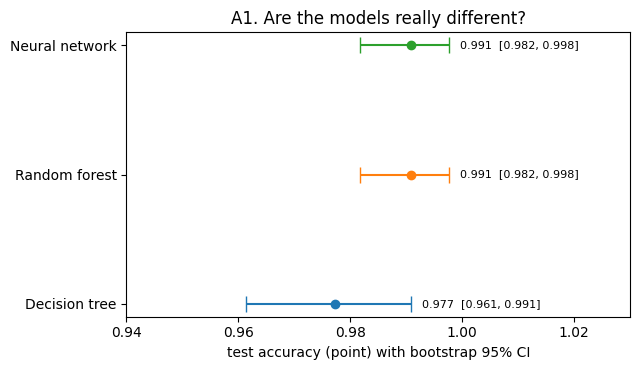

{
 "Decision tree": {
  "accuracy": 0.9773,
  "ci95": [
   0.9614,
   0.9909
  ]
 },
 "Random forest": {
  "accuracy": 0.9909,
  "ci95": [
   0.9818,
   0.9977
  ]
 },
 "Neural network": {
  "accuracy": 0.9909,
  "ci95": [
   0.9818,
   0.9977
  ]
 }
}


In [21]:
rng = np.random.default_rng(SEED)
correct = {k: (p == yte.values).astype(float) for k, p in pred.items()}
n = len(yte)
boot = {k: [c[rng.integers(0, n, n)].mean() for _ in range(2000)] for k, c in correct.items()}
A["bootstrap_accuracy_ci95"] = {k: {"accuracy": round(float(correct[k].mean()), 4),
                                    "ci95": [round(float(np.percentile(b, 2.5)), 4), round(float(np.percentile(b, 97.5)), 4)]}
                                for k, b in boot.items()}
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, (k, v) in enumerate(A["bootstrap_accuracy_ci95"].items()):
    ax.errorbar(v["accuracy"], i, xerr=[[v["accuracy"] - v["ci95"][0]], [v["ci95"][1] - v["accuracy"]]], fmt="o", capsize=6)
    ax.text(v["ci95"][1] + 0.002, i, f'{v["accuracy"]:.3f}  [{v["ci95"][0]:.3f}, {v["ci95"][1]:.3f}]', va="center", fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels(A["bootstrap_accuracy_ci95"]); ax.set_xlim(0.94, 1.03)
ax.set_xlabel("test accuracy (point) with bootstrap 95% CI"); ax.set_title("A1. Are the models really different?")
plt.tight_layout(); plt.savefig(FIG / "stat_bootstrap_ci.png", dpi=120); plt.show()
print(json.dumps(A["bootstrap_accuracy_ci95"], indent=1))

## A2. McNemar's exact test - do two models make different mistakes on the same test fields?
**What:** for a pair of models, count fields where only model 1 is right (b) and only model 2 is right (c). Under "the
models are equally good", b and c should be about equal; an exact binomial test on b vs b+c gives the p-value.
**Why:** it is the standard paired test for two classifiers on one test set. p < 0.05 means a real difference.


In [22]:
names = list(models)
A["mcnemar_exact"] = {}
for i in range(3):
    for j in range(i + 1, 3):
        a, b_ = correct[names[i]], correct[names[j]]
        only_a, only_b = int(((a == 1) & (b_ == 0)).sum()), int(((a == 0) & (b_ == 1)).sum())
        p = 1.0 if only_a + only_b == 0 else float(stats.binomtest(only_a, only_a + only_b, 0.5).pvalue)
        A["mcnemar_exact"][f"{names[i]} vs {names[j]}"] = {"only_first_right": only_a, "only_second_right": only_b,
                                                             "p": round(p, 6), "significant_at_5pct": p < 0.05}
print(json.dumps(A["mcnemar_exact"], indent=1))

{
 "Decision tree vs Random forest": {
  "only_first_right": 0,
  "only_second_right": 6,
  "p": 0.03125,
  "significant_at_5pct": true
 },
 "Decision tree vs Neural network": {
  "only_first_right": 3,
  "only_second_right": 9,
  "p": 0.145996,
  "significant_at_5pct": false
 },
 "Random forest vs Neural network": {
  "only_first_right": 3,
  "only_second_right": 3,
  "p": 1.0,
  "significant_at_5pct": false
 }
}


## A3. Repeated 5-fold cross-validation + paired tests
**What:** instead of one split, train each model on 15 different train/test splits (5 folds x 3 repeats) and compare the
15 paired accuracies with a paired t-test and a Wilcoxon signed-rank test.
**Caveat:** CV folds share training data, so the p-values are optimistic; read them together with A1/A2.


In [23]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scores = {k: cross_val_score(mk(), X, y, cv=cv, n_jobs=-1) for k, mk in
          [("Decision tree", mk_dt), ("Random forest", mk_rf), ("Neural network", mk_mlp)]}
A["repeated_cv_accuracy"] = {k: {"mean": round(float(s.mean()), 4), "std": round(float(s.std()), 4)} for k, s in scores.items()}
A["paired_tests_on_cv"] = {}
for i in range(3):
    for j in range(i + 1, 3):
        a, b_ = scores[names[i]], scores[names[j]]
        t = stats.ttest_rel(a, b_)
        w = stats.wilcoxon(a, b_) if np.any(a != b_) else None
        A["paired_tests_on_cv"][f"{names[i]} vs {names[j]}"] = {
            "mean_diff": round(float((a - b_).mean()), 4), "paired_t_p": round(float(t.pvalue), 6),
            "wilcoxon_p": None if w is None else round(float(w.pvalue), 6)}
print(json.dumps({k: A[k] for k in ("repeated_cv_accuracy", "paired_tests_on_cv")}, indent=1))

{
 "repeated_cv_accuracy": {
  "Decision tree": {
   "mean": 0.9865,
   "std": 0.0047
  },
  "Random forest": {
   "mean": 0.9947,
   "std": 0.0031
  },
  "Neural network": {
   "mean": 0.9861,
   "std": 0.0041
  }
 },
 "paired_tests_on_cv": {
  "Decision tree vs Random forest": {
   "mean_diff": -0.0082,
   "paired_t_p": 2.8e-05,
   "wilcoxon_p": 0.001406
  },
  "Decision tree vs Neural network": {
   "mean_diff": 0.0005,
   "paired_t_p": 0.710188,
   "wilcoxon_p": 0.534925
  },
  "Random forest vs Neural network": {
   "mean_diff": 0.0086,
   "paired_t_p": 7e-06,
   "wilcoxon_p": 0.000635
  }
 }
}


## A4. Effect size: how strongly does each feature separate the 22 crops? (ANOVA eta-squared)
**What:** for each feature, eta^2 = (variance *between* crops) / (total variance), from a one-way ANOVA with crop as the
group. 0 = crop tells you nothing about the feature, 1 = crop fully determines it.
**Why:** 01_prepare.py gave ANOVA p-values (all tiny, because n is large). Effect size says *how much*, which p cannot.
It also explains the feature importance seen in 02 (rainfall, humidity and K matter most).


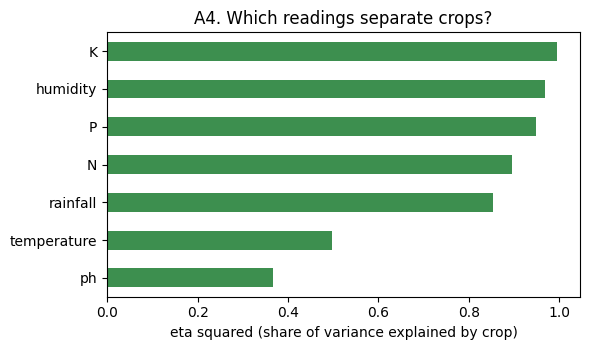

{'N': 0.8964, 'P': 0.9479, 'K': 0.9962, 'temperature': 0.4963, 'humidity': 0.9677, 'ph': 0.3678, 'rainfall': 0.8538}


In [24]:
eta2 = {}
for f in FEATURES:
    groups = [g[f].values for _, g in crop.groupby("label")]
    grand = crop[f].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    sst = ((crop[f] - grand) ** 2).sum()
    eta2[f] = round(float(ssb / sst), 4)
A["anova_eta_squared"] = eta2
pd.Series(eta2).sort_values().plot.barh(figsize=(6, 3.6), color="#3d8f4f")
plt.xlabel("eta squared (share of variance explained by crop)"); plt.title("A4. Which readings separate crops?")
plt.tight_layout(); plt.savefig(FIG / "stat_eta2.png", dpi=120); plt.show()
print(eta2)

# Part B - Ablation study
An ablation study removes one component at a time and measures the damage. Components that cost nothing to remove are
candidates to delete; components whose removal hurts are justified.
## B1. Leave-one-feature-out (random forest, 5-fold CV accuracy)
**What:** retrain the forest without one reading (or one group: nutrients N/P/K, climate temp/humidity/rainfall, pH) and
compare with the full 7-feature model. **Why:** shows which sensors a farmer really needs. A cheap sensor whose removal
costs almost nothing could be dropped on a low-cost device.


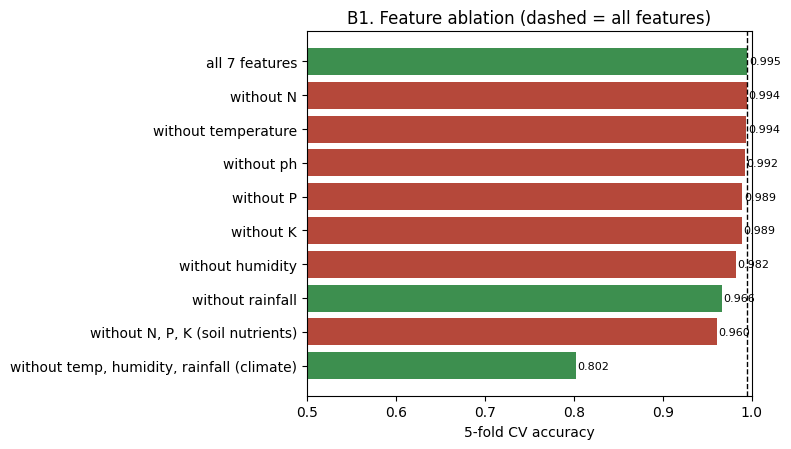

                                              mean     std  change_vs_full
all 7 features                              0.9950  0.0027          0.0000
without N                                   0.9941  0.0034         -0.0009
without P                                   0.9891  0.0027         -0.0059
without K                                   0.9886  0.0041         -0.0064
without temperature                         0.9936  0.0022         -0.0014
without humidity                            0.9818  0.0035         -0.0132
without ph                                  0.9923  0.0037         -0.0027
without rainfall                            0.9664  0.0081         -0.0286
without N, P, K (soil nutrients)            0.9605  0.0059         -0.0345
without temp, humidity, rainfall (climate)  0.8023  0.0096         -0.1927


In [25]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cvacc = lambda cols: cross_val_score(mk_rf(), X[cols], y, cv=skf, n_jobs=-1)
full = cvacc(FEATURES)
abl = {"all 7 features": full}
for f in FEATURES:
    abl[f"without {f}"] = cvacc([c for c in FEATURES if c != f])
groups = {"without N, P, K (soil nutrients)": ["N", "P", "K"], "without temp, humidity, rainfall (climate)": ["temperature", "humidity", "rainfall"]}
for k, drop in groups.items():
    abl[k] = cvacc([c for c in FEATURES if c not in drop])
A["ablation_features_rf_cv"] = {k: {"mean": round(float(v.mean()), 4), "std": round(float(v.std()), 4),
                                    "change_vs_full": round(float(v.mean() - full.mean()), 4)} for k, v in abl.items()}
s = pd.Series({k: v.mean() for k, v in abl.items()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(s.index, s.values, color=["#b5483a" if "all" not in k else "#3d8f4f" for k in s.index])
ax.set_xlim(0.5, 1.0); ax.axvline(full.mean(), color="k", ls="--", lw=1)
for i, v in enumerate(s.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("5-fold CV accuracy"); ax.set_title("B1. Feature ablation (dashed = all features)")
plt.tight_layout(); plt.savefig(FIG / "ablation_features.png", dpi=120); plt.show()
print(pd.DataFrame(A["ablation_features_rf_cv"]).T.round(4).to_string())

## B2. Ablating model size (number of trees) - the Edge AI trade-off
**What:** accuracy of a forest with 1, 3, 5, 10, 30, 100 trees (test set), and its approximate size = total tree nodes.
**Why:** the web app ships the forest to the browser, so fewer trees means a smaller download. We pick the knee of the
curve (30 trees).


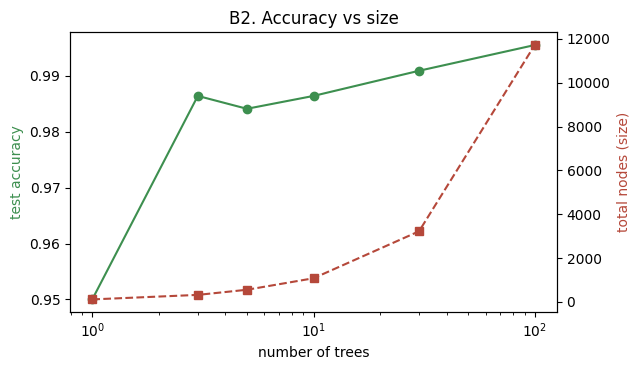

 trees  accuracy  nodes
     1    0.9500    111
     3    0.9864    317
     5    0.9841    551
    10    0.9864   1076
    30    0.9909   3220
   100    0.9955  11720


In [26]:
ntrees = [1, 3, 5, 10, 30, 100]
res = []
for k in ntrees:
    m = RandomForestClassifier(n_estimators=k, max_depth=10, random_state=SEED).fit(Xtr, ytr)
    res.append({"trees": k, "accuracy": round(float(m.score(Xte, yte)), 4), "nodes": int(sum(e.tree_.node_count for e in m.estimators_))})
A["ablation_forest_size"] = res
fig, ax = plt.subplots(figsize=(6.5, 3.8)); ax2 = ax.twinx()
ax.plot(ntrees, [r["accuracy"] for r in res], "o-", color="#3d8f4f"); ax2.plot(ntrees, [r["nodes"] for r in res], "s--", color="#b5483a")
ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_ylabel("test accuracy", color="#3d8f4f"); ax2.set_ylabel("total nodes (size)", color="#b5483a")
ax.set_title("B2. Accuracy vs size"); plt.tight_layout(); plt.savefig(FIG / "ablation_forest_size.png", dpi=120); plt.show()
print(pd.DataFrame(res).to_string(index=False))

## B3. Ablating the suitability model
The suitability score (see 01b/02) is trained on the **synthetic** crop dataset. Three components are tested, all on the
*same held-out synthetic rows* as 02:
* **Full model** - gradient boosting, monotone constraint, all row types.
* **No monotone constraint** - same model but free to bend. Measured by *monotone violations*: take a random field, push one
  reading 1.5x further from the crop's typical value, and count how often the score wrongly *rises*.
* **Only good + other-crop rows** - trained without the marginal examples (blends, one-reading-off, single-extreme rows).
* **Classifier only (no suitability model)** - use the random forest's probability for that crop as the score.

Metrics: R2 and MAE against the synthetic label, violations, and the independent check `argmax_matches_real_label`
(on **real** held-out fields, is the top-scoring crop the true crop?).


                                          R2     MAE  monotone_violation_rate  argmax_matches_real_label
Full model (monotone, all rows)       0.9488  0.0464                   0.0000                     0.9727
No monotone constraint                0.9920  0.0196                   0.1567                     0.9773
Only good + other-crop rows           0.7445  0.0982                   0.0000                     0.9682
Classifier only (forest probability)  0.5320  0.1696                   0.0050                     0.9909


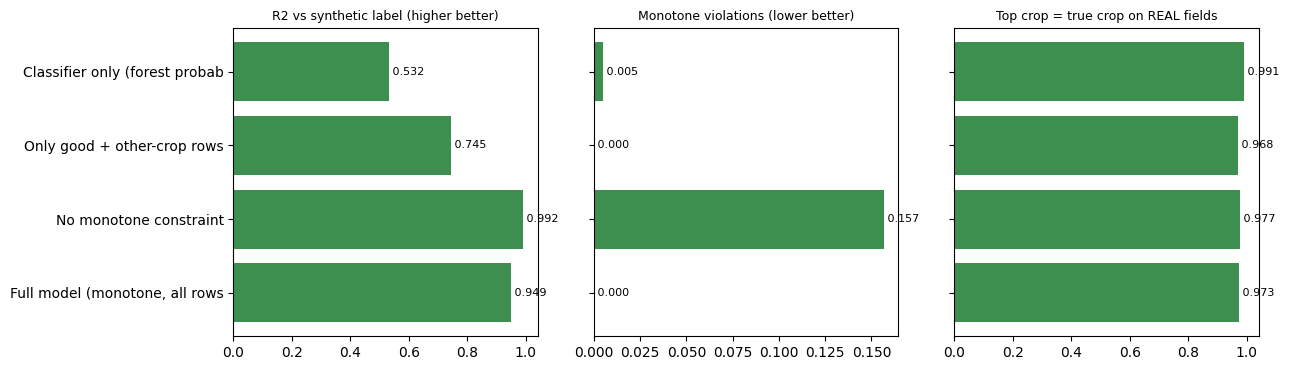

In [27]:
syn = pd.read_csv(PROC / "synthetic_crop_dataset.csv")
profile = json.loads((PROC / "crop_profile.json").read_text())
cls = sorted(crop.label.unique())
med = {c: np.array(profile[c]["med"]) for c in cls}; sc = {c: np.array(profile[c]["scale"]) for c in cls}
zabs = lambda c, Xm: np.abs(np.clip((np.asarray(Xm, float) - med[c]) / sc[c], -6, 6))
idx_tr, idx_te = train_test_split(np.arange(len(syn)), test_size=0.2, stratify=syn.crop, random_state=SEED)
Zall = np.array([zabs(c, r) for c, r in zip(syn.crop, syn[FEATURES].values)])


def fit_hgb(rows, mono=True):
    return HistGradientBoostingRegressor(monotonic_cst=[-1] * 7 if mono else None, max_iter=300, max_leaf_nodes=12,
                                         learning_rate=0.1, random_state=SEED).fit(Zall[rows], syn.suitability.values[rows])


rf_full = models["Random forest"]
variants = {
    "Full model (monotone, all rows)": (lambda c, Xm, m=fit_hgb(idx_tr): np.clip(m.predict(zabs(c, Xm)), 0, 1)),
    "No monotone constraint": (lambda c, Xm, m=fit_hgb(idx_tr, mono=False): np.clip(m.predict(zabs(c, Xm)), 0, 1)),
    "Only good + other-crop rows": (lambda c, Xm, m=fit_hgb(np.array([i for i in idx_tr if syn.how_generated[i] in ("real_good", "other_crop")])):
                                        np.clip(m.predict(zabs(c, Xm)), 0, 1)),
    "Classifier only (forest probability)": (lambda c, Xm: rf_full.predict_proba(np.asarray(Xm, float))[:, list(rf_full.classes_).index(c)]),
}
te = syn.iloc[idx_te]
rrng = np.random.default_rng(7)
viol_cases = []
for _ in range(600):
    c = cls[rrng.integers(len(cls))]; x = med[c] + (rrng.random(7) * 8 - 4) * sc[c]; i = rrng.integers(7)
    y2 = x.copy(); y2[i] = med[c][i] + (x[i] - med[c][i]) * 1.5
    viol_cases.append((c, x, y2))
real_te = Xte.values
abl_s = {}
for name, fn in variants.items():
    pred_s = np.concatenate([fn(c, g[FEATURES].values) for c, g in te.groupby("crop")])
    true_s = np.concatenate([g.suitability.values for _, g in te.groupby("crop")])
    viol = np.mean([float(fn(c, y2.reshape(1, -1))[0] > fn(c, x.reshape(1, -1))[0] + 1e-9) for c, x, y2 in viol_cases])
    top = np.array(cls)[np.argmax(np.column_stack([fn(c, real_te) for c in cls]), axis=1)]
    abl_s[name] = {"R2": round(float(r2_score(true_s, pred_s)), 4), "MAE": round(float(mean_absolute_error(true_s, pred_s)), 4),
                   "monotone_violation_rate": round(float(viol), 4), "argmax_matches_real_label": round(float((top == yte.values).mean()), 4)}
A["ablation_suitability"] = abl_s
df = pd.DataFrame(abl_s).T
print(df.to_string())
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a_, col, ttl in zip(ax, ["R2", "monotone_violation_rate", "argmax_matches_real_label"],
                        ["R2 vs synthetic label (higher better)", "Monotone violations (lower better)", "Top crop = true crop on REAL fields"]):
    a_.barh(range(len(df)), df[col], color="#3d8f4f"); a_.set_yticks(range(len(df)))
    a_.set_yticklabels([s[:30] for s in df.index] if col == "R2" else [""] * len(df)); a_.set_title(ttl, fontsize=9)
    for i, v in enumerate(df[col]):
        a_.text(v, i, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "ablation_suitability.png", dpi=120); plt.show()

### B3 figure: the score as one reading improves
Rice, rainfall swept from 20 to 300 mm with every other reading fixed at rice's typical value. The full model rises
smoothly and never dips; the unconstrained model can wobble; the classifier-only score jumps because forests are
piecewise-constant and know nothing about "bad" fields.


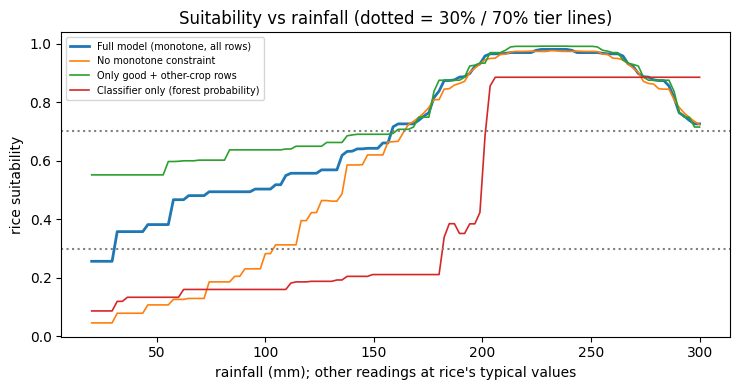

In [28]:
sweep = np.linspace(20, 300, 120)
base = med["rice"].copy()
pts = np.tile(base, (len(sweep), 1)); pts[:, 6] = sweep
plt.figure(figsize=(7.5, 4))
for name, fn in variants.items():
    plt.plot(sweep, fn("rice", pts), label=name, lw=2 if name.startswith("Full") else 1.2)
plt.axhline(0.3, color="grey", ls=":"); plt.axhline(0.7, color="grey", ls=":")
plt.xlabel("rainfall (mm); other readings at rice's typical values"); plt.ylabel("rice suitability"); plt.legend(fontsize=7)
plt.title("Suitability vs rainfall (dotted = 30% / 70% tier lines)"); plt.tight_layout()
plt.savefig(FIG / "suitability_curve.png", dpi=120); plt.show()

# Part C - Cross-dataset validation
**What:** test the models on a *different* dataset than the one they were trained on.
**Dataset used:** `Jakehills/Crop_Yield_Fertilizer` on Hugging Face - 25,000 rows, same 7 features and 22 crops. It was
checked in this project: 2,199 of its rows are exactly our original rows; the other ~22,800 are **augmented** rows with a
wider spread (e.g. rice temperature 14-31 C instead of 20-27 C). We call those 22,800 the *external* set.
**Honest limit:** the external rows are derived from the same Kaggle source, so this tests robustness to a wider,
shifted distribution, **not** independence from the original source. No fully independent public dataset with these exact
7 columns and 22 crops was found.
**Directions:** (1) train on ours, test on external. (2) train on external, test on our original rows.
The file is downloaded to `data/external/` (not committed to git); if there is no internet this part is skipped.


In [29]:
EXT.mkdir(parents=True, exist_ok=True)
f_ext = EXT / "Crop_Yield_Fertilizer.csv"
URL = "https://huggingface.co/datasets/Jakehills/Crop_Yield_Fertilizer/resolve/main/Crop_Yield_Fertilizer.csv"
try:
    if not f_ext.exists():
        urllib.request.urlretrieve(URL, f_ext)
    ext_all = pd.read_csv(f_ext)
    ok = True
except Exception as e:  # offline: skip, do not fail the notebook
    ok = False
    A["cross_dataset"] = f"skipped (could not download): {e}"
    print(A["cross_dataset"])

In [30]:
if ok:
    key = lambda d: d[FEATURES].astype(float).round(4).astype(str).agg("|".join, axis=1) + "|" + d["label"]
    orig_keys = set(key(crop)); ext_all["k"] = key(ext_all)
    ext = ext_all[~ext_all.k.isin(orig_keys)].reset_index(drop=True)
    Xe, ye = ext[FEATURES], ext.label
    # (1) train on ours (train split), evaluate in-dataset (our test split) and on the external set
    cd = {"external_rows": len(ext), "overlap_with_original_rows": int(len(ext_all) - len(ext))}
    cd["train_ours_test_external"] = {}
    for k, m in models.items():
        cd["train_ours_test_external"][k] = {"in_dataset_accuracy": round(float((m.predict(Xte) == yte.values).mean()), 4),
                                             "external_accuracy": round(float((m.predict(Xe) == ye.values).mean()), 4)}
    sfn = variants["Full model (monotone, all rows)"]
    top_e = np.array(cls)[np.argmax(np.column_stack([sfn(c, Xe.values) for c in cls]), axis=1)]
    cd["train_ours_test_external"]["Suitability (top crop)"] = {
        "in_dataset_accuracy": round(float((np.array(cls)[np.argmax(np.column_stack([sfn(c, Xte.values) for c in cls]), axis=1)] == yte.values).mean()), 4),
        "external_accuracy": round(float((top_e == ye.values).mean()), 4)}
    # (2) train on a stratified 2,200-row sample of external (same size as ours), test on our ORIGINAL rows
    samp = ext.groupby("label", group_keys=False).apply(lambda g: g.sample(100, random_state=SEED))
    cd["train_external_test_ours"] = {}
    for k, mk in [("Decision tree", mk_dt), ("Random forest", mk_rf), ("Neural network", mk_mlp)]:
        m = mk().fit(samp[FEATURES], samp.label)
        cd["train_external_test_ours"][k] = {"accuracy_on_original_rows": round(float((m.predict(X) == y.values).mean()), 4)}
    # distribution shift per feature: two-sample Kolmogorov-Smirnov (0 = same distribution, 1 = completely different)
    cd["ks_shift_per_feature"] = {f: round(float(stats.ks_2samp(crop[f], ext[f]).statistic), 3) for f in FEATURES}
    A["cross_dataset"] = cd
    print(json.dumps(cd, indent=1))

{
 "external_rows": 22800,
 "overlap_with_original_rows": 2200,
 "train_ours_test_external": {
  "Decision tree": {
   "in_dataset_accuracy": 0.9773,
   "external_accuracy": 0.7159
  },
  "Random forest": {
   "in_dataset_accuracy": 0.9909,
   "external_accuracy": 0.8414
  },
  "Neural network": {
   "in_dataset_accuracy": 0.9909,
   "external_accuracy": 0.8853
  },
  "Suitability (top crop)": {
   "in_dataset_accuracy": 0.9727,
   "external_accuracy": 0.9139
  }
 },
 "train_external_test_ours": {
  "Decision tree": {
   "accuracy_on_original_rows": 0.9595
  },
  "Random forest": {
   "accuracy_on_original_rows": 0.9786
  },
  "Neural network": {
   "accuracy_on_original_rows": 0.9768
  }
 },
 "ks_shift_per_feature": {
  "N": 0.034,
  "P": 0.027,
  "K": 0.091,
  "temperature": 0.049,
  "humidity": 0.071,
  "ph": 0.044,
  "rainfall": 0.054
 }
}


### Cross-dataset figure
Left: accuracy when tested on our own held-out rows vs the external set (trained on ours). A small drop means the model
generalises to wider conditions; a large drop means it memorised our narrow ranges. Right: how far each feature's
distribution moved (KS statistic).


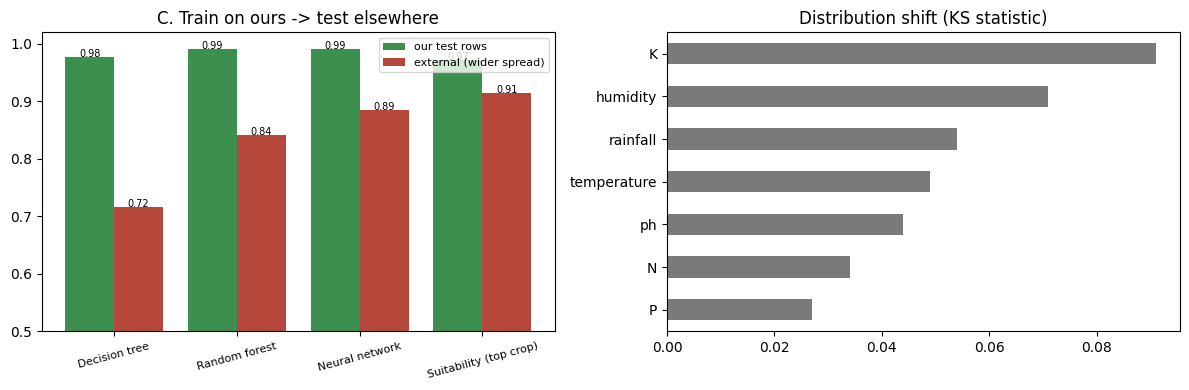

In [31]:
if ok:
    t = pd.DataFrame(cd["train_ours_test_external"]).T
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    xs = np.arange(len(t))
    ax[0].bar(xs - 0.2, t.in_dataset_accuracy, 0.4, label="our test rows", color="#3d8f4f")
    ax[0].bar(xs + 0.2, t.external_accuracy, 0.4, label="external (wider spread)", color="#b5483a")
    ax[0].set_xticks(xs); ax[0].set_xticklabels(t.index, rotation=15, fontsize=8); ax[0].set_ylim(0.5, 1.02); ax[0].legend(fontsize=8)
    for i, (a_, b_) in enumerate(zip(t.in_dataset_accuracy, t.external_accuracy)):
        ax[0].text(i - 0.2, a_, f"{a_:.2f}", ha="center", fontsize=7); ax[0].text(i + 0.2, b_, f"{b_:.2f}", ha="center", fontsize=7)
    ax[0].set_title("C. Train on ours -> test elsewhere")
    pd.Series(cd["ks_shift_per_feature"]).sort_values().plot.barh(ax=ax[1], color="#7a7a7a"); ax[1].set_title("Distribution shift (KS statistic)")
    plt.tight_layout(); plt.savefig(FIG / "cross_dataset.png", dpi=120); plt.show()

In [32]:
(MODELS / "analysis.json").write_text(json.dumps(A, indent=2, default=str))
print("saved analysis.json with sections:", list(A))

saved analysis.json with sections: ['bootstrap_accuracy_ci95', 'mcnemar_exact', 'repeated_cv_accuracy', 'paired_tests_on_cv', 'anova_eta_squared', 'ablation_features_rf_cv', 'ablation_forest_size', 'ablation_suitability', 'cross_dataset']
